In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

date_column = ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]

listings = pd.read_csv("data/listings_clean.csv", parse_dates=date_column)

print(listings.shape)

(4574, 73)


What does the distribution of the price look like?

histogram

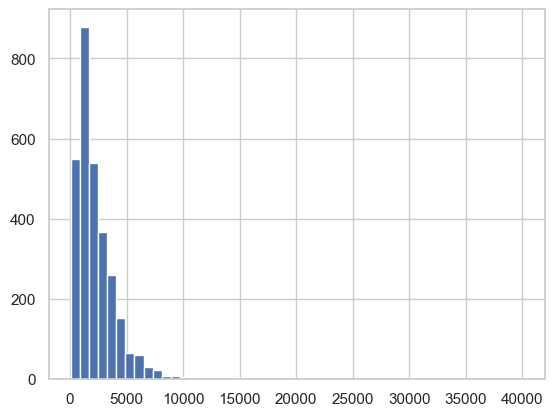

In [3]:
fig, ax = plt.subplots()

ax.hist(listings["price"].dropna(), bins=50)
plt.show()

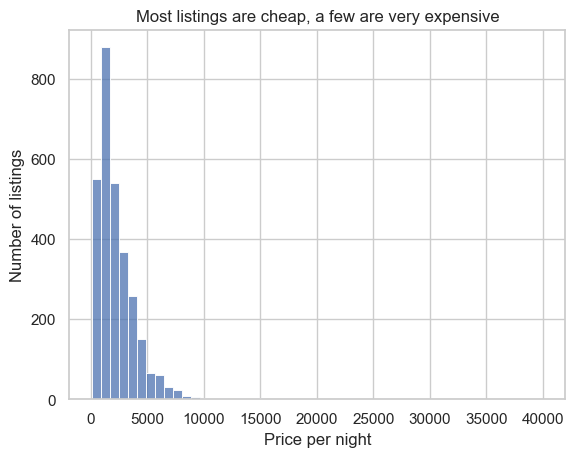

In [4]:
fig, ax = plt.subplots()
sns.histplot(data=listings, x="price", bins=50, ax=ax)

ax.set_title("Most listings are cheap, a few are very expensive")
ax.set_xlabel("Price per night")
ax.set_ylabel("Number of listings")

plt.show()

The histogram: see the shape of the price

In [ ]:
q1 = listings["price"].quantile(0.25)
q3 = listings["price"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)

listings["price_outlier"] = listings["price"] > upper

print(round(upper, 1), listings["price_outlier"].sum())


5902.8 132


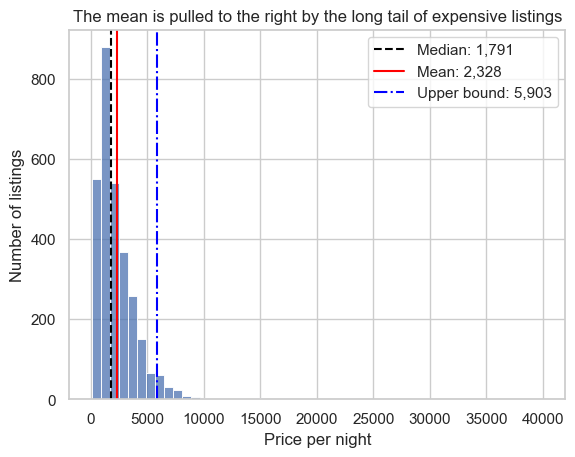

In [6]:
median = listings["price"].median()
mean = listings["price"].mean()

fig, ax = plt.subplots()
sns.histplot(data=listings, x="price", bins=50, ax=ax)
ax.axvline(median, color="black", linestyle="--", label=f"Median: {median:,.0f}")
ax.axvline(mean, color="red", linestyle="-", label=f"Mean: {mean:,.0f}")
ax.axvline(upper, color="blue", linestyle="-.", label=f"Upper bound: {upper:,.0f}")

ax.set_title("The mean is pulled to the right by the long tail of expensive listings")
ax.set_xlabel("Price per night")
ax.set_ylabel("Number of listings")

ax.legend()
plt.show()

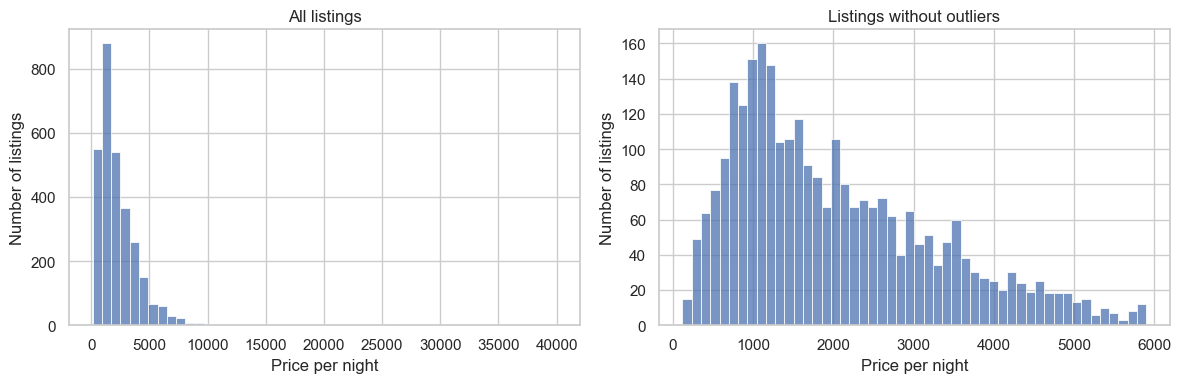

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=listings, x="price", bins=50, ax=axes[0])
sns.histplot(data=listings[~listings["price_outlier"]], x="price", bins=50, ax=axes[1])

axes[0].set_title("All listings")
axes[1].set_title("Listings without outliers")

for ax in axes:
    ax.set_xlabel("Price per night")
    ax.set_ylabel("Number of listings")


plt.tight_layout()
plt.show()

##The boxplot: see the outliers

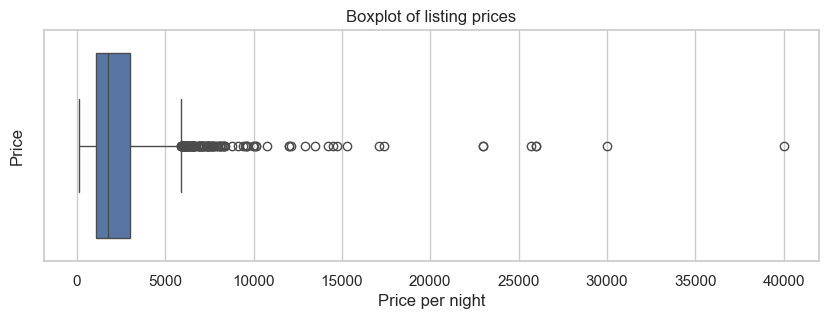

In [12]:
fig, ax = plt.subplots(figsize=(10, 3))

sns.boxplot(data=listings, x="price", ax=ax)
ax.set_title("Boxplot of listing prices")
ax.set_xlabel("Price per night")
ax.set_ylabel("Price")

plt.show()